**NEPAL FLOOD & WEATHER ANALYSIS**

**Import Libraries**

In [1123]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,f1_score,precision_score,recall_score,accuracy_score
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

Data Loading

In [1124]:
df=pd.read_csv('/content/CORRECTED_2023_2026_NEPAL_FLOOD_WEATHER_KAGGLE.csv')
df.head()

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,rain_mm,temperature_mean_c,dew_point_mean_c,precipitation_hours,relative_humidity_mean_pct,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s
0,2023-01-01 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,12.2,-2.6,0,37,13.9,68.0,187,0.22
1,2023-01-02 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,11.1,-4.8,0,34,13.4,69.8,191,0.21
2,2023-01-03 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,11.5,-10.3,0,22,14.5,72.0,183,0.21
3,2023-01-04 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,9.6,-8.9,0,29,11.2,67.7,187,0.20
4,2023-01-05 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,10.1,-10.2,0,26,7.4,69.8,54,0.20


In [1125]:
df.tail()

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,rain_mm,temperature_mean_c,dew_point_mean_c,precipitation_hours,relative_humidity_mean_pct,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s
13385,2026-08-31 00:00:00,Chisapani,Karnali,Karnali,280.00,28.653056,81.286944,2215,16.3,0.392,16.3,28.3,26.2,21,89,7.1,27.7,90,2.22
13386,2026-08-31 00:00:00,Devghat,Narayani,Narayani/Gandak,450.00,27.710000,84.430000,603,42.8,0.361,42.8,28.3,26.5,22,91,9.1,24.8,89,4.43
13387,2026-08-31 00:00:00,Khokana,Bagmati,Bagmati,550.05,27.632222,85.293333,1315,29.8,0.412,29.8,23.4,21.8,17,92,6.9,20.9,317,4.09
13388,2026-08-31 00:00:00,Kusum,West Rapti,Rapti,375.00,28.007500,82.093889,230,20.3,0.419,20.3,27.7,26.3,18,93,9.6,28.8,87,621.30
13389,2026-08-31 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,5.5,0.411,5.5,23.9,20.6,18,82,4.4,33.5,246,3.60


In [1126]:
df.shape

(13390, 19)

Data Understanding

In [1127]:
#1. Identify the target variable for the prediction.

target='river_discharge_m3s'

In [1128]:
#2. Identify the numerical and categorical variables.
num_cols=df.select_dtypes(include=np.number).columns.tolist()
cat_cols=df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:")
print(num_cols)
print("\nCategorical columns:")
print(cat_cols)

Numerical columns:
['dhm_station', 'latitude', 'longitude', 'elevation_m', 'precipitation_mm', 'soil_moisture_0_100cm_m3m3', 'rain_mm', 'temperature_mean_c', 'dew_point_mean_c', 'precipitation_hours', 'relative_humidity_mean_pct', 'wind_speed_max_kmh', 'wind_gusts_max_kmh', 'wind_direction_dominant_deg', 'river_discharge_m3s']

Categorical columns:
['date', 'location', 'river', 'basin']


In [1129]:
#3. Check the dataset for missing values and duplicate records.



In [1130]:
df.isna().sum()

,0
date,0
location,0
river,0
basin,0
dhm_station,0
latitude,0
longitude,0
elevation_m,0
precipitation_mm,0
soil_moisture_0_100cm_m3m3,0


In [1131]:
df.duplicated().sum()

np.int64(0)

In [1132]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13390 entries, 0 to 13389
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   date                         13390 non-null  object 
 1   location                     13390 non-null  object 
 2   river                        13390 non-null  object 
 3   basin                        13390 non-null  object 
 4   dhm_station                  13390 non-null  float64
 5   latitude                     13390 non-null  float64
 6   longitude                    13390 non-null  float64
 7   elevation_m                  13390 non-null  int64  
 8   precipitation_mm             13390 non-null  float64
 9   soil_moisture_0_100cm_m3m3   13390 non-null  float64
 10  rain_mm                      13390 non-null  float64
 11  temperature_mean_c           13390 non-null  float64
 12  dew_point_mean_c             13390 non-null  float64
 13  precipitation_ho

In [1133]:
df['date']=pd.to_datetime(df['date'])

In [1134]:
df.dtypes

,0
date,datetime64[ns]
location,object
river,object
basin,object
dhm_station,float64
latitude,float64
longitude,float64
elevation_m,int64
precipitation_mm,float64
soil_moisture_0_100cm_m3m3,float64


In [1135]:
df.duplicated(subset=["date", "location"]).sum()

np.int64(0)

In [1136]:
#4. Analyze the distribution of the river discharge variable.

In [1137]:
df['river_discharge_m3s'].describe()

,river_discharge_m3s
count,13390.000000
mean,20.372064
std,84.333629
min,0.000000
25%,0.260000
50%,1.880000
75%,10.530000
max,3175.870000


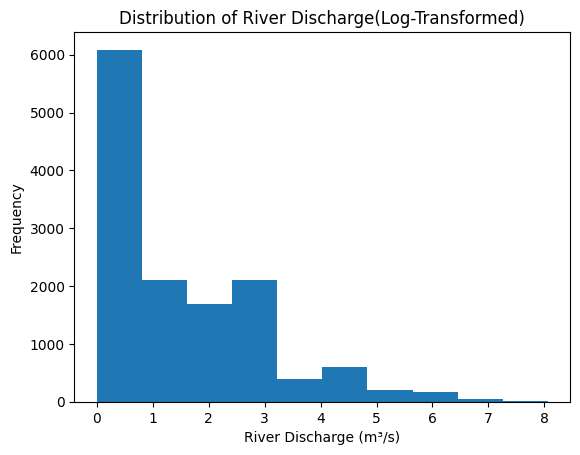

In [1138]:

plt.hist(np.log1p(df['river_discharge_m3s']),bins=10)
plt.xlabel('River Discharge (m³/s)')
plt.ylabel('Frequency')
plt.title('Distribution of River Discharge(Log-Transformed)')
plt.show()

In [1139]:
#Identify the river station/location with the highest average river discharge.

In [1140]:
avg_discharge=df.groupby('location')['river_discharge_m3s'].mean().sort_values(ascending=False)
avg_discharge

,river_discharge_m3s
location,
Kusum,125.812158
Belsot,33.032636
Chameliya/Nayalbadi,31.393465
Bahrabise,5.051314
Devghat,2.331277
Khokana,1.658006
Chatara,1.491344
Rasuwagadhi,1.406751
Chisapani,0.847072


**Exploratory Data Analysis**

In [1141]:
#6. Analyze the relationship between rainfall/precipitation and river discharge.

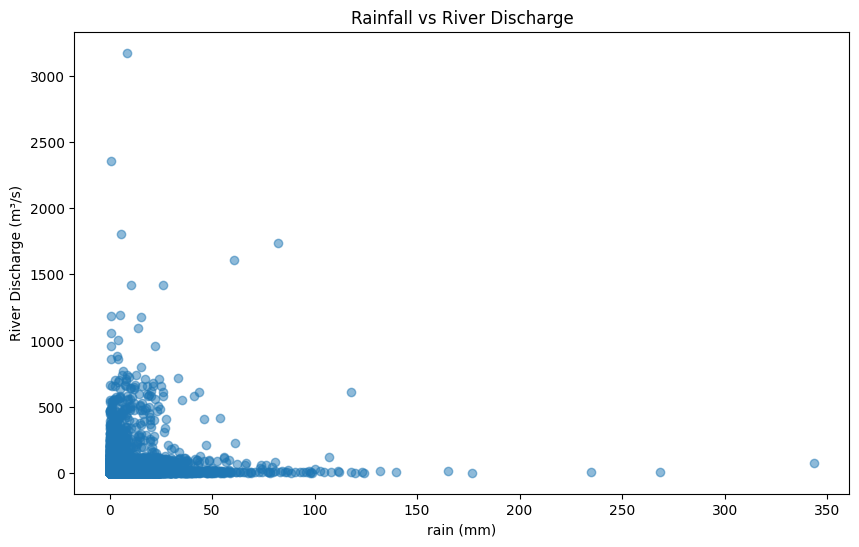

In [1142]:
plt.figure(figsize=(10, 6))
plt.scatter(df['rain_mm'], df['river_discharge_m3s'], alpha=0.5)
plt.xlabel("rain (mm)")
plt.ylabel('River Discharge (m³/s)')
plt.title('Rainfall vs River Discharge')

plt.show()

In [1143]:
#7. Identify which weather variable has the strongest relationship with river discharge.

In [1144]:
weather_cols=["precipitation_mm", "rain_mm", "soil_moisture_0_100cm_m3m3", "temperature_mean_c",
                "dew_point_mean_c", "precipitation_hours", "relative_humidity_mean_pct",
                "wind_speed_max_kmh", "wind_gusts_max_kmh", "wind_direction_dominant_deg"]

In [1145]:
corr = df[weather_cols + ["river_discharge_m3s"]].corr()["river_discharge_m3s"].drop("river_discharge_m3s")
corr = corr.sort_values(ascending=False)
corr

,river_discharge_m3s
dew_point_mean_c,0.226308
temperature_mean_c,0.178499
relative_humidity_mean_pct,0.171687
soil_moisture_0_100cm_m3m3,0.151942
precipitation_hours,0.145097
rain_mm,0.099743
precipitation_mm,0.098626
wind_speed_max_kmh,0.051560
wind_gusts_max_kmh,-0.009484
wind_direction_dominant_deg,-0.040901


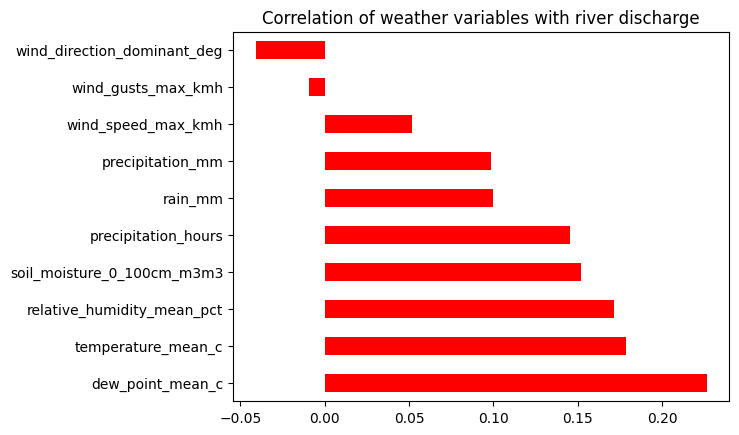

In [1146]:
corr = df[weather_cols + ["river_discharge_m3s"]].corr()["river_discharge_m3s"].drop("river_discharge_m3s")
corr = corr.sort_values(ascending=False)
corr.plot(kind="barh", color="red", title="Correlation of weather variables with river discharge")
plt.show()

In [1147]:
#8. Compare river discharge across different river stations/locations.

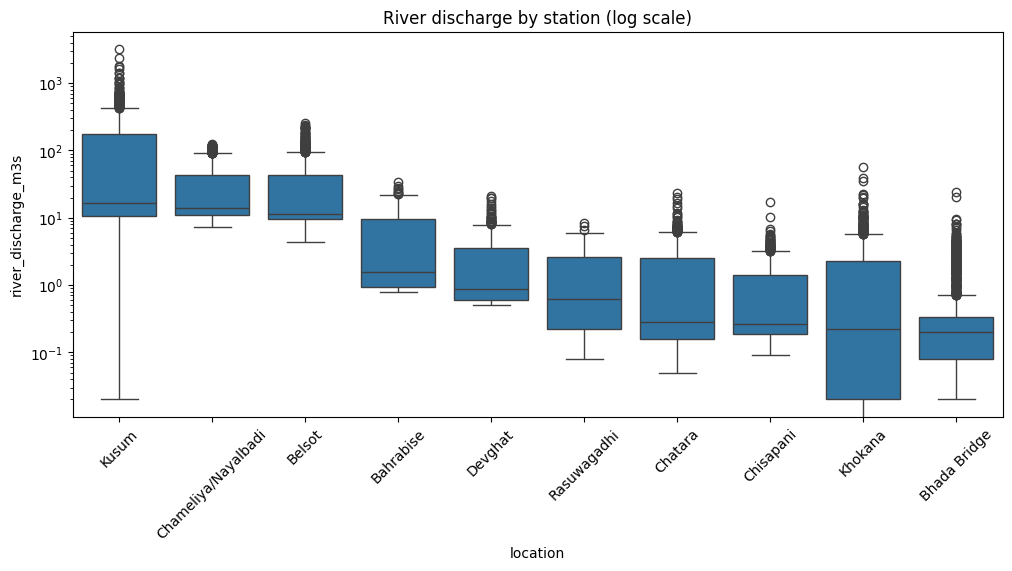

In [1148]:
plt.figure(figsize=(12, 5))
order = df.groupby("location")["river_discharge_m3s"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="location", y="river_discharge_m3s", order=order)
plt.yscale("log"); plt.xticks(rotation=45)
plt.title("River discharge by station (log scale)")
plt.show()

In [1149]:
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}:       {len(outliers)} outliers")

dhm_station:       0 outliers
latitude:       1339 outliers
longitude:       0 outliers
elevation_m:       0 outliers
precipitation_mm:       1860 outliers
soil_moisture_0_100cm_m3m3:       23 outliers
rain_mm:       1915 outliers
temperature_mean_c:       0 outliers
dew_point_mean_c:       71 outliers
precipitation_hours:       345 outliers
relative_humidity_mean_pct:       96 outliers
wind_speed_max_kmh:       522 outliers
wind_gusts_max_kmh:       832 outliers
wind_direction_dominant_deg:       0 outliers
river_discharge_m3s:       1379 outliers


In [1150]:
#9. Analyze the monthly or seasonal pattern of river discharge.

In [1151]:
df['month']=df['date'].dt.month
monthly_discharge=df.groupby('month')['river_discharge_m3s'].mean()
monthly_discharge

,river_discharge_m3s
month,
1,4.309758
2,3.801097
3,3.533565
4,3.200350
5,3.251137
6,6.312908
7,53.719702
8,72.464669
9,52.970000


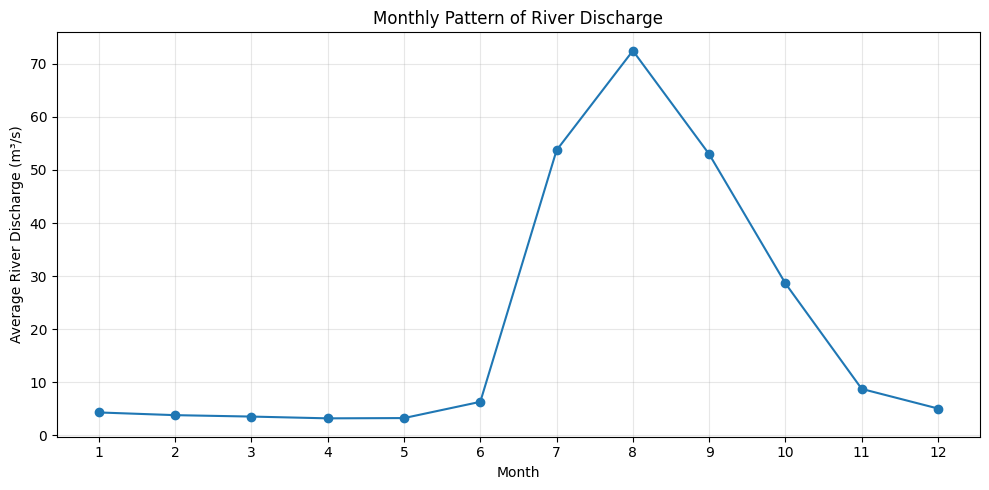

In [1152]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 13),
    monthly_discharge.values,
    marker="o"
)
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Average River Discharge (m³/s)")
plt.title("Monthly Pattern of River Discharge")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [1153]:
#10. Identify periods with unusually high river discharge.

In [1154]:
df['unusually_high']=df['river_discharge_m3s']>df.groupby('location')['river_discharge_m3s'].transform(lambda x: x.quantile(0.95))


In [1155]:
df.groupby('month')['unusually_high'].sum()

,unusually_high
month,
1,0
2,0
3,0
4,0
5,0
6,7
7,174
8,346
9,88


In [1156]:
df.nlargest(10, "river_discharge_m3s")[["date", "location", "precipitation_mm", "river_discharge_m3s"]]

,date,location,precipitation_mm,river_discharge_m3s
6368,2024-09-28,Kusum,8.4,3175.87
6378,2024-09-29,Kusum,0.9,2359.48
2374,2023-07-04,Kusum,5.6,1802.02
5538,2024-07-07,Kusum,82.0,1736.80
5528,2024-07-06,Kusum,60.9,1609.65
2371,2023-07-01,Kusum,25.8,1421.33
5548,2024-07-08,Kusum,10.2,1418.06
9568,2025-08-14,Kusum,4.9,1190.24
2375,2023-07-05,Kusum,0.8,1182.04
9478,2025-08-05,Kusum,15.2,1173.90


# Feature Engineering

In [1157]:
#11. Create lag features for rainfall, such as previous-day, previous 2-day, and previous 3 day rainfall.

In [1158]:
df=df.sort_values(['location','date']).reset_index(drop=True)

In [1159]:
g=df.groupby('location')

In [1160]:
df.columns

Index(['date', 'location', 'river', 'basin', 'dhm_station', 'latitude',
       'longitude', 'elevation_m', 'precipitation_mm',
       'soil_moisture_0_100cm_m3m3', 'rain_mm', 'temperature_mean_c',
       'dew_point_mean_c', 'precipitation_hours', 'relative_humidity_mean_pct',
       'wind_speed_max_kmh', 'wind_gusts_max_kmh',
       'wind_direction_dominant_deg', 'river_discharge_m3s', 'month',
       'unusually_high'],
      dtype='object')

In [1161]:
df['rain_lag_1']=g['rain_mm'].shift(1)
df['rain_lag_2']=g['rain_mm'].shift(2)
df['rain_lag_3']=g['rain_mm'].shift(3)
df.head()


,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,...,relative_humidity_mean_pct,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s,month,unusually_high,rain_lag_1,rain_lag_2,rain_lag_3
0,2023-01-01,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.291,...,71,7.8,24.1,106,1.05,1,False,NaN,NaN,NaN
1,2023-01-02,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.303,...,73,7.3,25.2,80,1.05,1,False,0.0,NaN,NaN
2,2023-01-03,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.306,...,65,7.9,24.1,89,1.01,1,False,0.0,0.0,NaN
3,2023-01-04,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,61,8.0,22.3,77,0.99,1,False,0.0,0.0,0.0
4,2023-01-05,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,55,5.9,21.6,67,0.97,1,False,0.0,0.0,0.0


In [1162]:
#12. Create rolling rainfall features such as 3-day and 7-day rainfall totals/averages.

In [1163]:
df['rain_sum_3d']=g['rain_mm'].transform(lambda x: x.shift(1).rolling(3).sum())
df['rain_sum_7d']=g['rain_mm'].transform(lambda x: x.shift(1).rolling(7).sum())
df['rain_mean_7d']=g['rain_mm'].transform(lambda x: x.shift(1).rolling(7).mean())
df.head()

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,...,wind_direction_dominant_deg,river_discharge_m3s,month,unusually_high,rain_lag_1,rain_lag_2,rain_lag_3,rain_sum_3d,rain_sum_7d,rain_mean_7d
0,2023-01-01,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.291,...,106,1.05,1,False,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-02,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.303,...,80,1.05,1,False,0.0,NaN,NaN,NaN,NaN,NaN
2,2023-01-03,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.306,...,89,1.01,1,False,0.0,0.0,NaN,NaN,NaN,NaN
3,2023-01-04,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,77,0.99,1,False,0.0,0.0,0.0,0.0,NaN,NaN
4,2023-01-05,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,67,0.97,1,False,0.0,0.0,0.0,0.0,NaN,NaN


In [1164]:
#13. Create previous-day river discharge features.

In [1165]:
df['river_discharge_lag_1']=g['river_discharge_m3s'].shift(1)
df['river_discharge_lag_2']=g['river_discharge_m3s'].shift(2)
df['river_discharge_mean_7d']=g['river_discharge_m3s'].transform(lambda x: x.shift(1).rolling(7).mean())


In [1166]:
#14. Extract useful date features such as year and month.

In [1167]:
df["year"]  = df["date"].dt.year                                         # year (2023–2026)
df["month"] = df["date"].dt.month

In [1168]:
df.isnull().sum()

,0
date,0
location,0
river,0
basin,0
dhm_station,0
latitude,0
longitude,0
elevation_m,0
precipitation_mm,0
soil_moisture_0_100cm_m3m3,0


In [1169]:
df=df.dropna()

In [1170]:
df.shape

(13320, 31)

In [1171]:
#15. Encode the river station/location variable for machine learning.

In [1172]:
loc_dummies = pd.get_dummies(df["location"], dtype=int)    # one-hot: one 0/1 column per station
df = pd.concat([df, loc_dummies], axis=1)

In [1173]:
df.head()

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,...,Bahrabise,Belsot,Bhada Bridge,Chameliya/Nayalbadi,Chatara,Chisapani,Devghat,Khokana,Kusum,Rasuwagadhi
7,2023-01-08,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.299,...,1,0,0,0,0,0,0,0,0,0
8,2023-01-09,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.297,...,1,0,0,0,0,0,0,0,0,0
9,2023-01-10,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.296,...,1,0,0,0,0,0,0,0,0,0
10,2023-01-11,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.295,...,1,0,0,0,0,0,0,0,0,0
11,2023-01-12,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.300,...,1,0,0,0,0,0,0,0,0,0


# Machine Learning Prediction

In [1174]:
#16. Create the target variable as the next day's river discharge.

In [1175]:
# df['target_next_day']=g['river_discharge_m3s'].shift(-1)

df = df.sort_values(["location", "date"]).copy()
df["target_next_day"] = (
    df.groupby("location")["river_discharge_m3s"].shift(-1)
)

df["target_date"] = (
    df.groupby("location")["date"].shift(-1)
)

In [1176]:
len(df)

13320

In [1177]:
df_model=df.dropna().reset_index(drop=True)
len(df_model)

13310

In [1178]:
df_model.to_csv("nepal_flood_processed.csv", index=False)

In [1179]:
df=df_model.copy()

In [1180]:
#17. Prepare the input features using weather conditions, historical discharge, date features, and location.

In [1181]:
baseline_features = weather_cols + ["river_discharge_m3s", "latitude", "longitude", "elevation_m"]   # raw columns only
engineered_features = (["rain_lag_1", "rain_lag_2", "rain_lag_3", "rain_sum_3d", "rain_sum_7d", "rain_mean_7d",
                        "river_discharge_lag_1", "river_discharge_lag_2", "river_discharge_mean_7d", "year", "month"]
                       + loc_dummies.columns.tolist())
full_features = baseline_features + engineered_features




In [1182]:
full_features

['precipitation_mm',
 'rain_mm',
 'soil_moisture_0_100cm_m3m3',
 'temperature_mean_c',
 'dew_point_mean_c',
 'precipitation_hours',
 'relative_humidity_mean_pct',
 'wind_speed_max_kmh',
 'wind_gusts_max_kmh',
 'wind_direction_dominant_deg',
 'river_discharge_m3s',
 'latitude',
 'longitude',
 'elevation_m',
 'rain_lag_1',
 'rain_lag_2',
 'rain_lag_3',
 'rain_sum_3d',
 'rain_sum_7d',
 'rain_mean_7d',
 'river_discharge_lag_1',
 'river_discharge_lag_2',
 'river_discharge_mean_7d',
 'year',
 'month',
 'Bahrabise',
 'Belsot',
 'Bhada Bridge',
 'Chameliya/Nayalbadi',
 'Chatara',
 'Chisapani',
 'Devghat',
 'Khokana',
 'Kusum',
 'Rasuwagadhi']

In [1183]:
df.shape

(13310, 43)

In [1184]:
#18. Split the data into training and testing sets using an appropriate time-based approach.

In [1185]:
# dates=np.sort(df['date'].unique())
# cutoff=dates[int(len(dates)*0.8)]

In [1186]:
# train=df[df['date']<cutoff]
# test=df[df['date']>=cutoff]


# Sort dates and choose the 80% cutoff
dates = np.sort(df["date"].unique())
cutoff = dates[int(len(dates) * 0.8)]


train = df[df["target_date"] < cutoff].copy()


test = df[df["target_date"] >= cutoff].copy()

print("Cutoff date:", cutoff)
print("Training date range:", train["target_date"].min(), "to", train["target_date"].max())
print("Testing date range:", test["target_date"].min(), "to", test["target_date"].max())

Cutoff date: 2025-12-07T00:00:00.000000000
Training date range: 2023-01-09 00:00:00 to 2025-12-06 00:00:00
Testing date range: 2025-12-07 00:00:00 to 2026-08-31 00:00:00


In [1187]:
train.shape

(10630, 43)

In [1188]:
test.shape

(2680, 43)

In [1189]:
print("Last training target date:", train["target_date"].max())
print("First test date:", test["target_date"].min())

assert train["target_date"].max() < cutoff
assert test["target_date"].min() >= cutoff

print("Train/test boundary verified!")

Last training target date: 2025-12-06 00:00:00
First test date: 2025-12-07 00:00:00
Train/test boundary verified!


In [1190]:

y_train, y_test = train["target_next_day"], test["target_next_day"]
X_train, X_test = train[full_features], test[full_features]
Xb_train, Xb_test = train[baseline_features], test[baseline_features]

In [1191]:
#20. Train a Linear Regression model

In [1192]:
lr_model=LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

In [1193]:
y_pred_lr=lr_model.predict(X_test)

In [1194]:
print("Predicted discharge:", y_pred_lr[:10])

print("Actual discharge:", y_test.iloc[:10].values)

Predicted discharge: [ 0.26662295  0.39744959 -1.16368688 -0.44683057  0.34355665 -0.30544744
 -0.57787745  0.14279517 -0.07528835  0.10161731]
Actual discharge: [1.77 1.7  1.64 1.58 1.52 1.47 1.4  1.36 1.31 1.26]


In [1195]:
#21. Train a Random Forest Regressor.

In [1196]:
rf_model=RandomForestRegressor(n_estimators=100, random_state=42,n_jobs=-1)
rf_model.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [1197]:
y_pred_rf=rf_model.predict(X_test)

In [1198]:
print("Predicted discharge:", y_pred_rf[:10])

print("Actual discharge:", y_test.iloc[:10].values)

Predicted discharge: [1.778  1.7255 1.6364 1.5819 1.5476 1.4883 1.4144 1.3642 1.3194 1.2774]
Actual discharge: [1.77 1.7  1.64 1.58 1.52 1.47 1.4  1.36 1.31 1.26]


In [1199]:
#22.Gradient Boost

In [1200]:
gb_model=GradientBoostingRegressor(n_estimators=200, random_state=42)
gb_model.fit(X_train, y_train)

GradientBoostingRegressor(n_estimators=200, random_state=42)

In [1201]:
y_pred_gb=gb_model.predict(X_test)

In [1202]:
print("Predicted discharge:", y_pred_gb[:10])

print("Actual discharge:", y_test.iloc[:10].values)

Predicted discharge: [1.47716219 1.47716219 1.47716219 1.47716219 1.23577407 1.23577407
 1.23577407 1.23577407 1.03894273 1.03894273]
Actual discharge: [1.77 1.7  1.64 1.58 1.52 1.47 1.4  1.36 1.31 1.26]


In [1203]:
#Decision Tree

In [1204]:
dt_model=DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [1205]:
y_pred_dt=dt_model.predict(X_test)

In [1206]:
print("Predicted discharge:", y_pred_dt[:10])

print("Actual discharge:", y_test.iloc[:10].values)

Predicted discharge: [1.79 1.71 1.65 1.56 1.55 1.48 1.4  1.38 1.32 1.28]
Actual discharge: [1.77 1.7  1.64 1.58 1.52 1.47 1.4  1.36 1.31 1.26]


In [1207]:
#23. Compare the models using MAE, MSE, RMSE, and R² Score.

In [1208]:
predictions = {
    "Linear Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
    "Decision Tree": y_pred_dt
}

results = []

for model_name, y_pred in predictions.items():

    # MAE: Average absolute prediction error
    mae = mean_absolute_error(y_test, y_pred)

    # MSE: Average squared prediction error
    mse = mean_squared_error(y_test, y_pred)

    # RMSE: Square root of MSE
    rmse = np.sqrt(mse)

    # R2: How well the model explains variation in actual discharge
    r2 = r2_score(y_test, y_pred)

    # Store the results
    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Sort models by RMSE, lowest first
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

# Display the comparison table
display(results_df.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,6.0606,226.3006,15.0433,0.9344
1,Random Forest,2.4167,277.3969,16.6552,0.9196
2,Gradient Boosting,2.8414,374.0599,19.3406,0.8916
3,Decision Tree,3.1119,532.8228,23.0830,0.8456


In [1209]:
#Best model= Random Forest
#Linear Regression has lowest rmse and highest r2_score but Random Forest has lowest MAE

# Model Evaluation & Interpretation

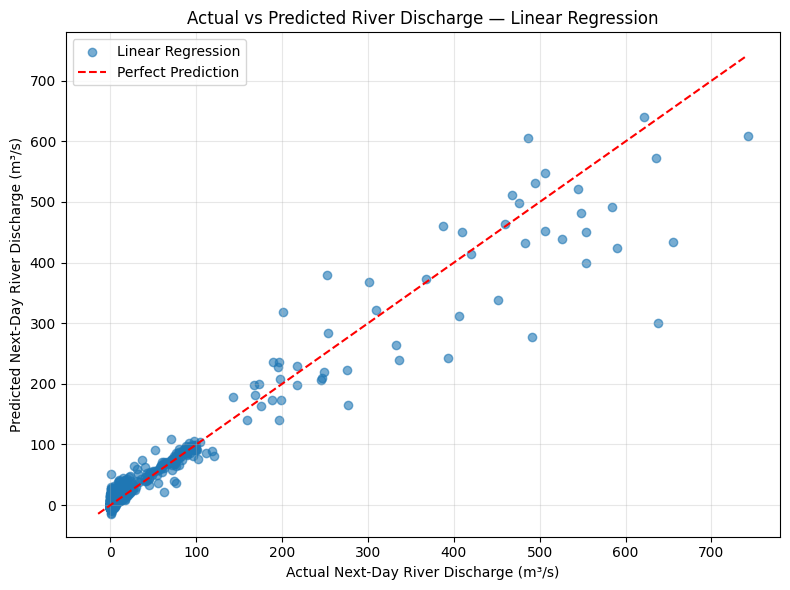

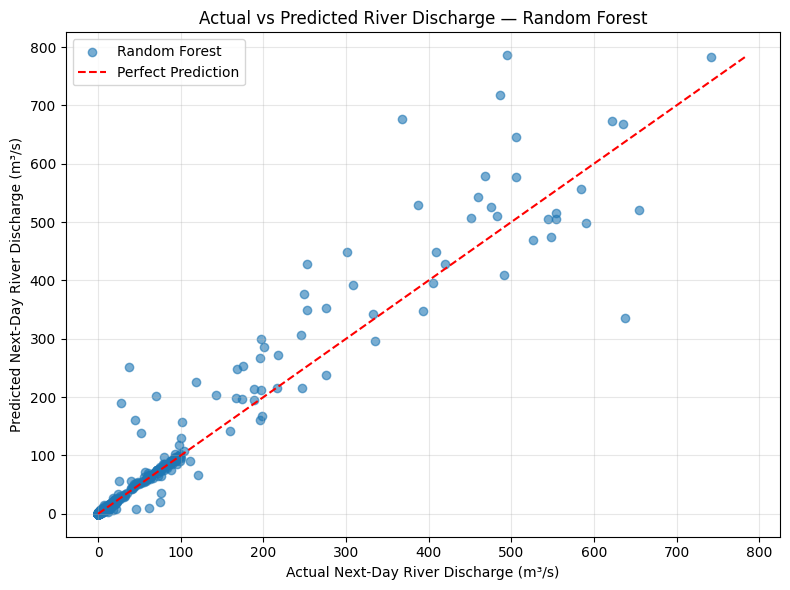

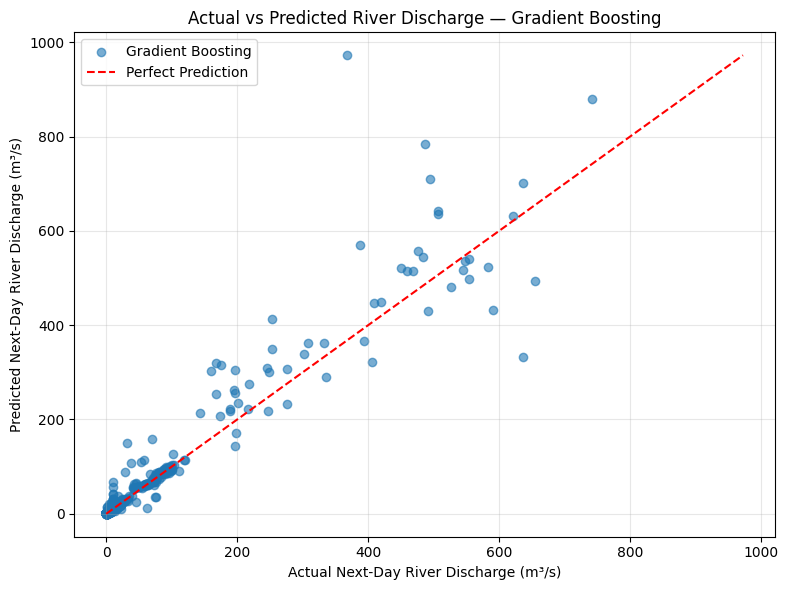

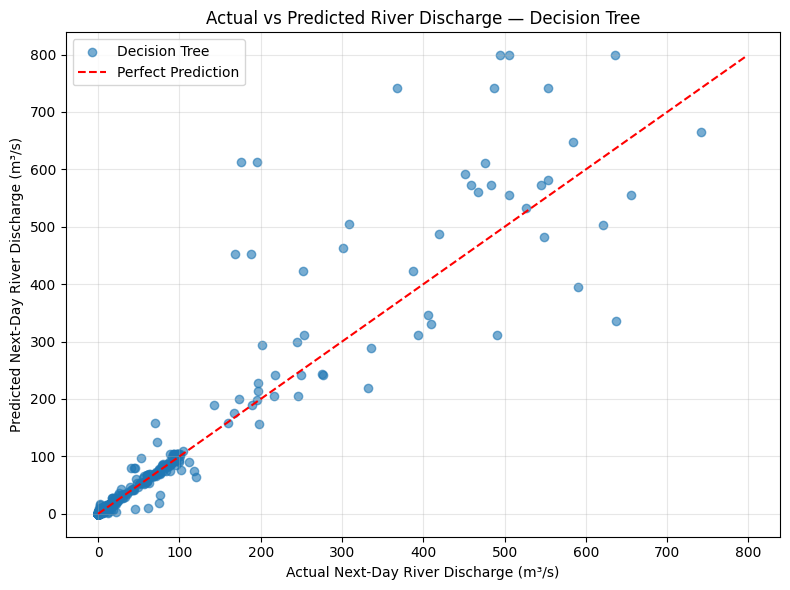

In [1210]:



for model_name, y_pred in predictions.items():
    plt.figure(figsize=(8, 6))
    plt.scatter(
        y_test,
        y_pred,
        alpha=0.6,
        label=model_name
    )

    min_value = min(np.min(y_test), np.min(y_pred))
    max_value = max(np.max(y_test), np.max(y_pred))



    plt.plot(
       [min_value, max_value],
       [min_value, max_value],
        color="red",
       linestyle="--",
       label="Perfect Prediction"
    )
    plt.xlabel("Actual Next-Day River Discharge (m³/s)")
    plt.ylabel("Predicted Next-Day River Discharge (m³/s)")
    plt.title(f"Actual vs Predicted River Discharge — {model_name}")

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()





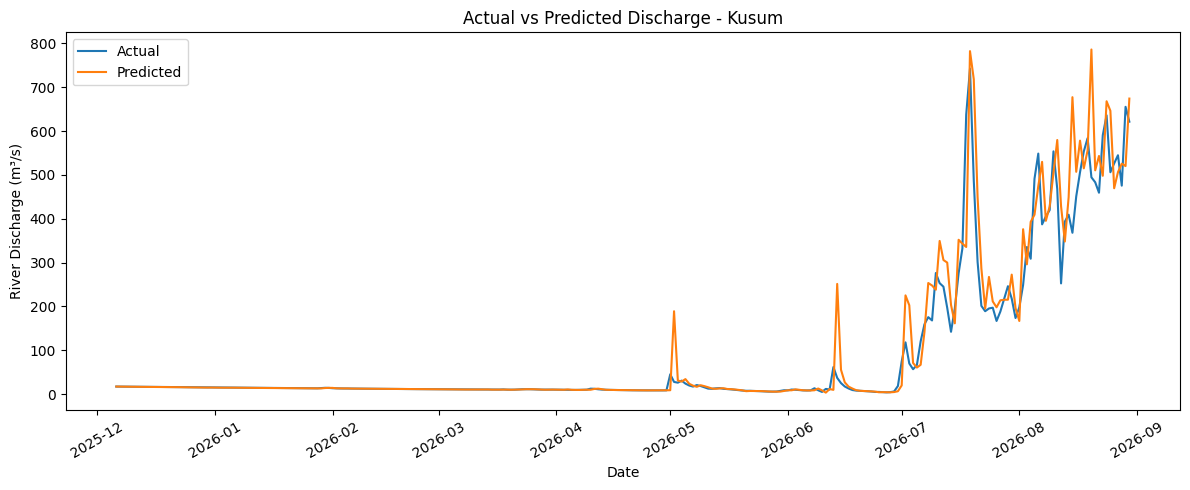

In [1211]:
top_station = avg_discharge.index[0]
mask = test["location"] == top_station

plt.figure(figsize=(12, 5))

plt.plot(test.loc[mask, "date"], y_test[mask], label="Actual")
plt.plot(test.loc[mask, "date"], y_pred_rf[mask], label="Predicted")

plt.title(f"Actual vs Predicted Discharge - {top_station}")
plt.xlabel("Date")
plt.ylabel("River Discharge (m³/s)")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

In [1212]:
#error analysis

In [1213]:
err = test[["date", "location"]].copy()
err['actual']=y_test.values
err['predicted']=y_pred_rf
err['error']=err['actual']-err['predicted']
err['abs_error']=abs(err['error'])

In [1214]:
err.nlargest(10, 'actual')

,date,location,actual,predicted,error,abs_error
11936,2026-07-19,Kusum,742.02,782.1789,-40.1589,40.1589
11977,2026-08-29,Kusum,655.15,520.0474,135.1026,135.1026
11935,2026-07-18,Kusum,637.26,335.5573,301.7027,301.7027
11972,2026-08-24,Kusum,635.80,667.8800,-32.0800,32.0800
11978,2026-08-30,Kusum,621.30,673.9755,-52.6755,52.6755
11971,2026-08-23,Kusum,590.56,497.9257,92.6343,92.6343
11967,2026-08-19,Kusum,583.79,555.8274,27.9626,27.9626
11958,2026-08-10,Kusum,553.63,504.8846,48.7454,48.7454
11966,2026-08-18,Kusum,553.63,514.8644,38.7656,38.7656
11954,2026-08-06,Kusum,548.54,474.5101,74.0299,74.0299


In [1215]:
#28. Identify the most important features affecting river discharge prediction.

In [1216]:

imp = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

imp = imp.sort_values(
    by="Importance",
    ascending=False
)


print("Top 10 Features Affecting River Discharge Prediction:")
print(imp.head(10).round(4))



Top 10 Features Affecting River Discharge Prediction:
                       Feature  Importance
10         river_discharge_m3s      0.8136
3           temperature_mean_c      0.0367
1                      rain_mm      0.0233
0             precipitation_mm      0.0210
22     river_discharge_mean_7d      0.0192
4             dew_point_mean_c      0.0169
5          precipitation_hours      0.0120
14                  rain_lag_1      0.0116
2   soil_moisture_0_100cm_m3m3      0.0104
20       river_discharge_lag_1      0.0049


In [1217]:
#29. Create a feature importance visualization for the best model.

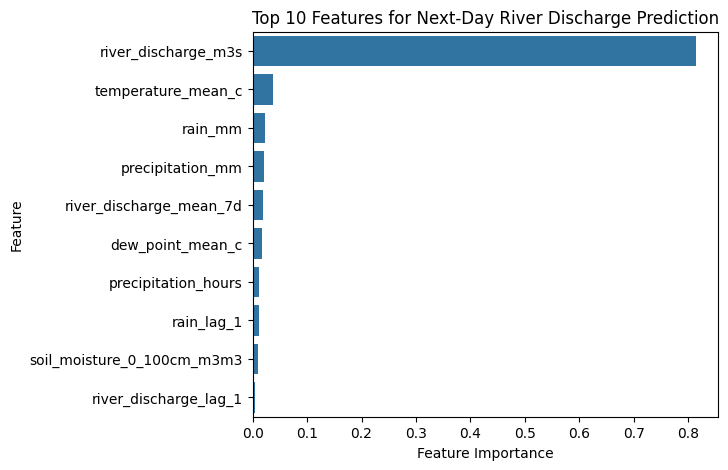

In [1218]:
top_features = imp.head(10).sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(6, 5))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features for Next-Day River Discharge Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

In [1219]:
#30. Compare model performance before and after feature engineering.

In [1220]:
# Baseline features
rf_baseline = RandomForestRegressor(
    n_estimators=100, random_state=42, n_jobs=-1
)

rf_baseline.fit(Xb_train, y_train)
y_pred_baseline = rf_baseline.predict(Xb_test)

# Compare baseline vs existing full-feature model
comparison = pd.DataFrame({
    "Model": ["Baseline", "With Feature Engineering"],
    "MAE": [
        mean_absolute_error(y_test, y_pred_baseline),
        mean_absolute_error(y_test, y_pred_rf)
    ],

    "MSE": [
        mean_squared_error(y_test, y_pred_baseline),
        mean_squared_error(y_test, y_pred_rf)],

    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_baseline)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],
    "R2 Score": [
        r2_score(y_test, y_pred_baseline),
        r2_score(y_test, y_pred_rf)
    ]
})

display(comparison.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Baseline,2.4708,317.5574,17.8201,0.9080
1,With Feature Engineering,2.4167,277.3969,16.6552,0.9196


In [1221]:
baseline_mae = comparison.loc[0, "MAE"]
engineered_mae = comparison.loc[1, "MAE"]

improvement = ((baseline_mae - engineered_mae) / baseline_mae) * 100

print(f"MAE improvement after feature engineering: {improvement:.2f}%")

MAE improvement after feature engineering: 2.19%


**High-Flow Classification**

In [1222]:
#31. Create a High Flow = 1 and Normal Flow = 0 target.

In [1223]:
thresholds = train.groupby("location")["river_discharge_m3s"].quantile(0.90)
print("High-flow thresholds (m³/s):\n", thresholds.round(2))

train_thr = train["location"].map(thresholds)
test_thr  = test["location"].map(thresholds)
yc_train = (train["target_next_day"] > train_thr).astype(int)
yc_test  = (test["target_next_day"]  > test_thr).astype(int)



High-flow thresholds (m³/s):
 location
Bahrabise               13.68
Belsot                  94.68
Bhada Bridge             2.66
Chameliya/Nayalbadi     92.29
Chatara                  4.57
Chisapani                2.63
Devghat                  6.29
Khokana                  5.00
Kusum                  427.75
Rasuwagadhi              3.59
Name: river_discharge_m3s, dtype: float64


In [1224]:
#32. Handle any class imbalance appropriately.

In [1225]:
print("\nClass balance (train):\n", yc_train.value_counts(normalize=True).round(3))
print("Class balance (test):\n",  yc_test.value_counts(normalize=True).round(3))



Class balance (train):
 0    0.9
1    0.1
Name: proportion, dtype: float64
Class balance (test):
 0    0.936
1    0.064
Name: proportion, dtype: float64


In [1226]:
#33. Train Logistic Regression, Decision Tree, and Random Forest classification models.

In [1230]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

lr_model=LogisticRegression(class_weight="balanced",max_iter=1000)
dt_model=DecisionTreeClassifier(class_weight="balanced",random_state=42)
rfc_model=RandomForestClassifier(n_estimators=200,class_weight="balanced",random_state=42,n_jobs=-1)



lr_model.fit(X_train_scaled,yc_train)
dt_model.fit(X_train,yc_train)
rfc_model.fit(X_train,yc_train)


lr_model_pred=lr_model.predict(X_test_scaled)
dt_model_pred=dt_model.predict(X_test)
rfc_model_pred=rfc_model.predict(X_test)


models={
    "Logistic Regression":(yc_test,lr_model_pred),
    "Decision Tree":(yc_test,dt_model_pred),
    "Random Forest":(yc_test,rfc_model_pred)

}


results=[]

for name, (actual, predicted) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1 Score": f1_score(actual, predicted, zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(3))







                     Accuracy  Precision  Recall  F1 Score
Model                                                     
Logistic Regression     0.840      0.287   1.000     0.446
Decision Tree           0.936      0.500   0.663     0.570
Random Forest           0.970      0.769   0.756     0.762


In [1231]:
#34. Evaluate the models using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix.

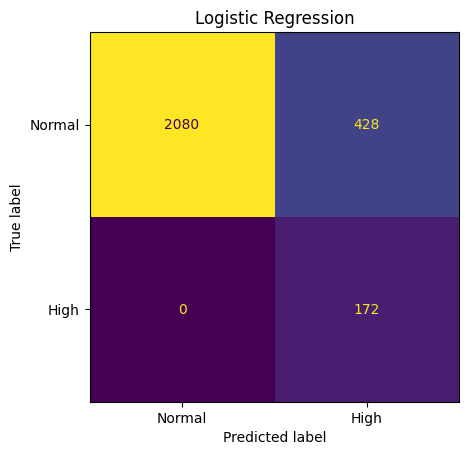

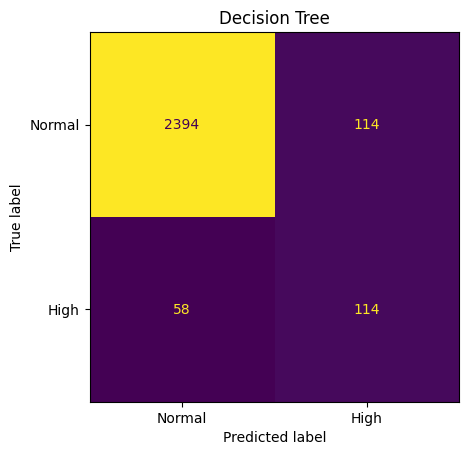

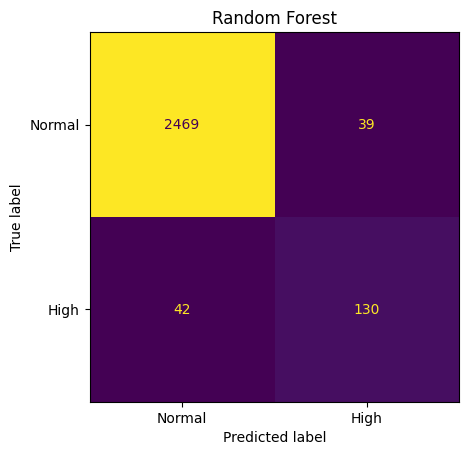

In [1232]:
#Logistic Regression
cm=confusion_matrix(yc_test,lr_model_pred)
ConfusionMatrixDisplay(cm, display_labels=["Normal", "High"]).plot(colorbar=False)
plt.title("Logistic Regression")
plt.show()


# Decision Tree
cm = confusion_matrix(yc_test, dt_model_pred)
ConfusionMatrixDisplay(cm, display_labels=["Normal", "High"]).plot(colorbar=False)
plt.title("Decision Tree")
plt.show()


# Random Forest
cm = confusion_matrix(yc_test, rfc_model_pred)
ConfusionMatrixDisplay(cm, display_labels=["Normal", "High"]).plot(colorbar=False)
plt.title("Random Forest")
plt.show()


In [1233]:
#35. Identify the best classification model.

In [1234]:
best_clf_model = results_df["F1 Score"].idxmax()
print("Best Classification Model:", best_clf_model)

Best Classification Model: Random Forest


In [1235]:
#36. Explain which features contribute most to high-flow prediction.

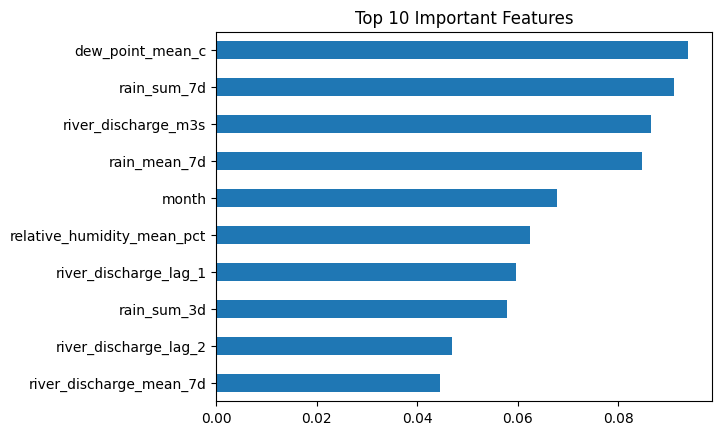

In [1236]:
importance = pd.Series(rfc_model.feature_importances_, index=full_features)

importance.nlargest(10).sort_values().plot(kind="barh", title="Top 10 Important Features")

plt.show()

In [1237]:
importance.sort_values(ascending=False).head(10)

,0
dew_point_mean_c,0.094004
rain_sum_7d,0.091031
river_discharge_m3s,0.086576
rain_mean_7d,0.084723
month,0.067747
relative_humidity_mean_pct,0.062499
river_discharge_lag_1,0.059645
rain_sum_3d,0.057902
river_discharge_lag_2,0.046923
river_discharge_mean_7d,0.044552


# Conclusion

**River discharge prediction**

The objective of this task was to predict next-day river discharge using weather conditions, historical river observations, seasonal features and station information.

The exploratory analysis showed strong seasonal variation, with average river discharge peaking in August at approximately 72.46 m³/s. Current river discharge was the dominant feature in the Random Forest feature-importance analysis, while temperature, rainfall, precipitation, dew point and historical discharge features also contributed to prediction.

Among the four regression models, Linear Regression achieved the lowest RMSE of 15.0433 m³/s and the highest R² score of 0.9344, while Random Forest achieved the lowest MAE of 2.4167 m³/s. Therefore, model performance depends on the evaluation metric: Linear Regression performed best on RMSE and R², whereas Random Forest produced the lowest average absolute error.

The feature-engineering experiment showed a 2.19% reduction in MAE and a 6.54% reduction in RMSE compared with the baseline-feature Random Forest. These results suggest that rainfall lags, rolling features, historical discharge features, seasonal information and station encoding provided a modest improvement in this experiment.

**High-flow classification**

The classification task aimed to predict whether the next day's river discharge would exceed a station-specific 90th-percentile threshold. The training data contained approximately 10% high-flow observations, compared with 6.4% in the test data, indicating class imbalance.

To address this imbalance, Logistic Regression, Decision Tree and Random Forest were trained using class weighting. In the saved results, Random Forest achieved the highest F1 score of 0.762, with an accuracy of 97.0%, precision of 76.9% and recall of 75.6%. It therefore provided the best balance between precision and recall among the three tested classifiers.

Logistic Regression achieved 100% recall but had a precision of only 28.7%, indicating that it identified all actual high-flow cases in the test set but generated considerably more false alarms. For flood-risk applications, recall is particularly important because missed high-flow events can have serious consequences. However, precision also matters because excessive false alarms may reduce confidence in the system.